# MultiSports, pallavolo: com'è fatto il dataset

**Domanda:** come sono strutturate le etichette di MultiSports per la pallavolo, quali
classi ci sono e come si legano ai video. Serve a decidere come ricondurre le sue
azioni ai nostri tocchi (issue #18).

Prima di eseguire, dalla cartella del progetto:

```
.venv/bin/python -m lib.multisports --femminili 10
```

Scarica le annotazioni (14 MB) e 10 clip femminili in `data/external/multisports/`,
fuori da git. Licenza del dataset: CC BY-NC 4.0.

In [1]:
import sys
from pathlib import Path

RADICE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RADICE))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

from lib import multisports as ms

gt = ms.carica_annotazioni()

## 1. Le chiavi del file

Un dizionario per tutti e quattro gli sport. `test_videos` è la validation: le
etichette del vero test set non sono pubbliche.

In [2]:
{chiave: type(valore).__name__ for chiave, valore in gt.items()}

{'labels': 'list',
 'train_videos': 'list',
 'test_videos': 'list',
 'nframes': 'dict',
 'resolution': 'dict',
 'gttubes': 'dict'}

## 2. Le classi della pallavolo

L'indice è la chiave usata in `gttubes`.

In [3]:
[(i, nome) for i, nome in enumerate(gt["labels"]) if nome.startswith("volleyball")]

[(21, 'volleyball serve'),
 (22, 'volleyball block'),
 (23, 'volleyball first pass'),
 (24, 'volleyball defend'),
 (25, 'volleyball protect'),
 (26, 'volleyball second pass'),
 (27, 'volleyball adjust'),
 (28, 'volleyball save'),
 (29, 'volleyball second attack'),
 (30, 'volleyball spike'),
 (31, 'volleyball dink'),
 (32, 'volleyball no offensive attack')]

## 3. Una riga per clip

Il genere viene da `docs/multisports-video.csv`, non dal dataset.

In [4]:
clip = pd.DataFrame(ms.clip_pallavolo(gt)).fillna(0)
clip.groupby(["genere", "parte"]).agg(clip=("clip", "size"), azioni=("azioni", "sum"))

clip  azioni
genere      parte                   
femminile   train        277    2547
            validation    70     718
maschile    train        115     885
            validation    40     385
sconosciuto train         10     117
            validation    20     191

In [5]:
classi = [c for c in clip.columns if c not in ("clip", "video", "parte", "genere", "fotogrammi", "azioni")]
clip.groupby("genere")[classi].sum().T.astype(int)

genere,femminile,maschile,sconosciuto
serve,339,154,30
defend,377,131,38
block,977,385,101
adjust,128,25,4
spike,458,174,42
first pass,319,142,28
second pass,434,182,45
second attack,16,8,2
dink,81,27,6
protect,56,11,5


## 4. Una traccia da vicino

Una traccia è un'azione di **una** giocatrice: una riga per fotogramma con
`fotogramma x1 y1 x2 y2`. Inizio e fine dell'azione sono la prima e l'ultima riga.

In [6]:
scelte = ms.scegli_clip(gt, "femminile", 10)
c = scelte[0]
print(c, "| fotogrammi:", gt["nframes"][c], "| risoluzione (h, w):", gt["resolution"][c])

indice_classe, tracce = next(iter(gt["gttubes"][c].items()))
traccia = tracce[0]
print(gt["labels"][indice_classe], "| righe:", len(traccia))
traccia[:5]

volleyball/v_2Dw9QNH5KtU_c008 | fotogrammi: 825 | risoluzione (h, w): (720, 1280)
volleyball first pass | righe: 13


array([[ 99.     , 533.3333 , 453.33334, 700.     , 689.3333 ],
       [100.     , 537.3333 , 442.66666, 704.     , 678.6667 ],
       [101.     , 540.     , 430.66666, 697.3333 , 656.6667 ],
       [102.     , 541.3333 , 416.66666, 698.6667 , 642.6667 ],
       [103.     , 542.6667 , 404.     , 700.     , 630.     ]],
      dtype=float32)

## 5. La linea del tempo di una clip

Ogni barra è un'azione di una giocatrice. Più muri sovrapposti sono più muratrici
sulla stessa palla.

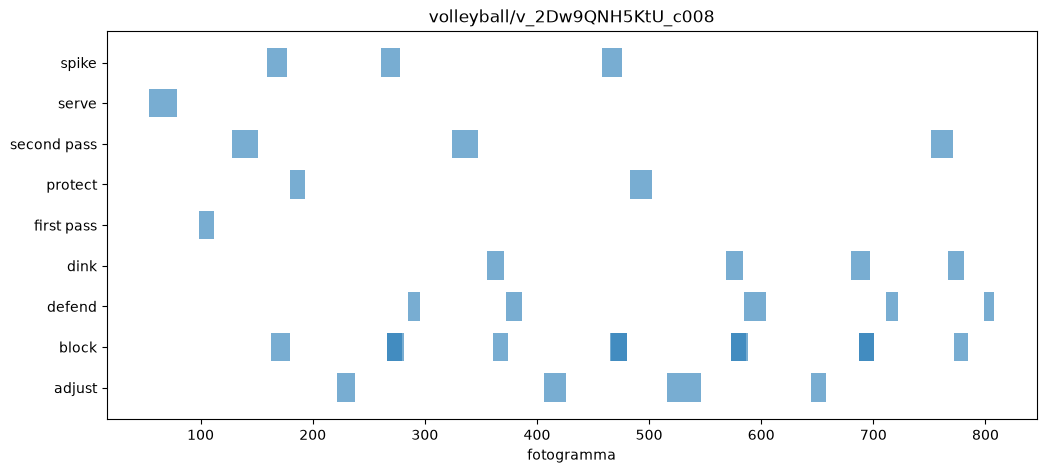

In [7]:
def linea_del_tempo(clip_nome):
    tracce = gt["gttubes"][clip_nome]
    nomi = sorted({gt["labels"][k].removeprefix("volleyball ") for k in tracce})
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(nomi) + 1))
    for k, lista in tracce.items():
        y = nomi.index(gt["labels"][k].removeprefix("volleyball "))
        for t in lista:
            ax.broken_barh([(t[0, 0], t[-1, 0] - t[0, 0] + 1)], (y - 0.35, 0.7), alpha=0.6)
    ax.set_yticks(range(len(nomi)), nomi)
    ax.set_xlabel("fotogramma")
    ax.set_title(clip_nome)
    plt.show()

linea_del_tempo(c)

## 6. Un fotogramma con le azioni in corso

Cambia `numero` per scorrere la clip. Il primo fotogramma è 1, come nelle annotazioni.

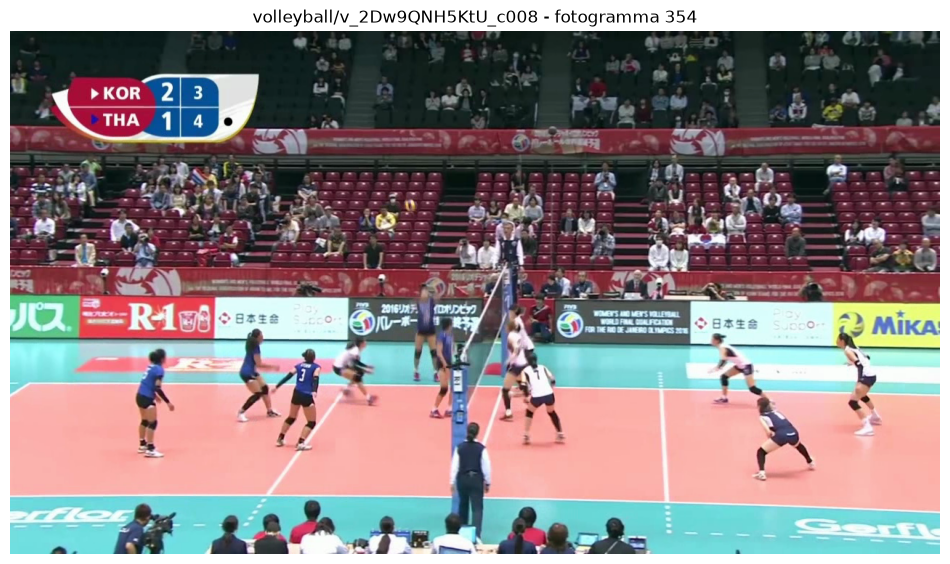

In [19]:
def mostra(clip_nome, numero):
    immagine = ms.fotogramma(clip_nome, numero)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(immagine)
    for classe, (x1, y1, x2, y2) in ms.azioni_nel_fotogramma(gt, clip_nome, numero):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, color="yellow"))
        ax.text(x1, y1 - 5, classe, color="black", backgroundcolor="yellow", fontsize=9)
    ax.set_title(f"{clip_nome} - fotogramma {numero}")
    ax.axis("off")
    plt.show()

# Il primo fotogramma della prima battuta della clip
indice_battuta = gt["labels"].index("volleyball serve")
prima_battuta = min(t[0, 0] for t in gt["gttubes"][c].get(indice_battuta, []))
numero = int(prima_battuta) + 300
mostra(c, numero)

## 7. Quanto dura un'azione

In fotogrammi; il dataset è annotato a 25 fps.

In [9]:
durate = [
    {"classe": gt["labels"][k].removeprefix("volleyball "), "fotogrammi": len(t)}
    for r in ms.clip_pallavolo(gt) if r["genere"] == "femminile"
    for k, lista in gt["gttubes"][r["clip"]].items()
    for t in lista
]
pd.DataFrame(durate).groupby("classe")["fotogrammi"].describe()[["count", "50%", "min", "max"]].astype(int)

,count,50%,min,max
classe,,,,
adjust,128,18,5,35
block,977,14,2,21
defend,377,14,4,44
dink,81,17,10,23
first pass,319,15,4,37
no offensive attack,46,19,5,33
protect,56,13,6,35
save,34,12,6,21
second attack,16,14,11,19


## Da capire guardando

- `first pass` è sempre una ricezione dopo la battuta, o anche un primo tocco in difesa?
- Un `block` c'è anche quando la muratrice non tocca la palla?
- Cosa sono `adjust`, `save` e `protect`, e a quale dei nostri tipi corrispondono?
- L'inizio di un'azione è il momento del tocco o del movimento che lo prepara (per la
  schiacciata: dallo stacco)? Per i nostri tocchi serve l'istante del contatto.